In [23]:
!pip install yfinance
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt

In [2]:
data = yf.download('AAPL', start='2022-01-01', end='2025-01-01')
print(data.head())

[*********************100%***********************]  1 of 1 completed

Price            Close        High         Low        Open     Volume
Ticker            AAPL        AAPL        AAPL        AAPL       AAPL
2022-01-03  177.786407  178.636229  173.586202  173.703413  104487900
2022-01-04  175.529984  178.694803  174.963441  178.391999   99310400
2022-01-05  170.860962  175.989135  170.587461  175.442132   94537600
2022-01-06  168.008682  171.232108  167.657036  168.692436   96904000
2022-01-07  168.174759  170.099046  167.061213  168.878052   86709100


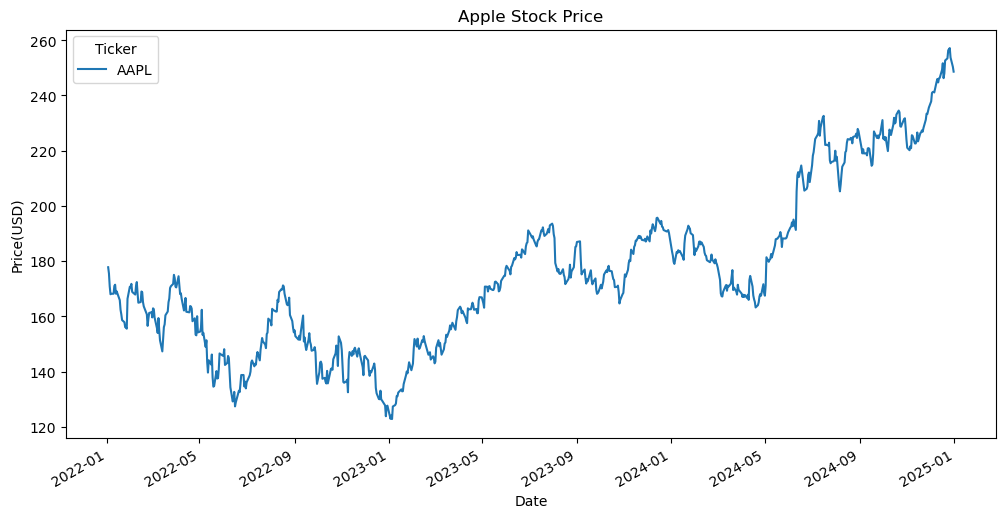

In [3]:
data['Close'].plot(figsize=(12,6),title='Apple Stock Price')
plt.xlabel('Date')
plt.ylabel('Price(USD)')
plt.show()

Ticker          AAPL
2022-01-03       NaN
2022-01-04 -0.012692
2022-01-05 -0.026600
2022-01-06 -0.016694
2022-01-07  0.000989
2022-01-10  0.000116
2022-01-11  0.016784
2022-01-12  0.002570
2022-01-13 -0.019028
2022-01-14  0.005111


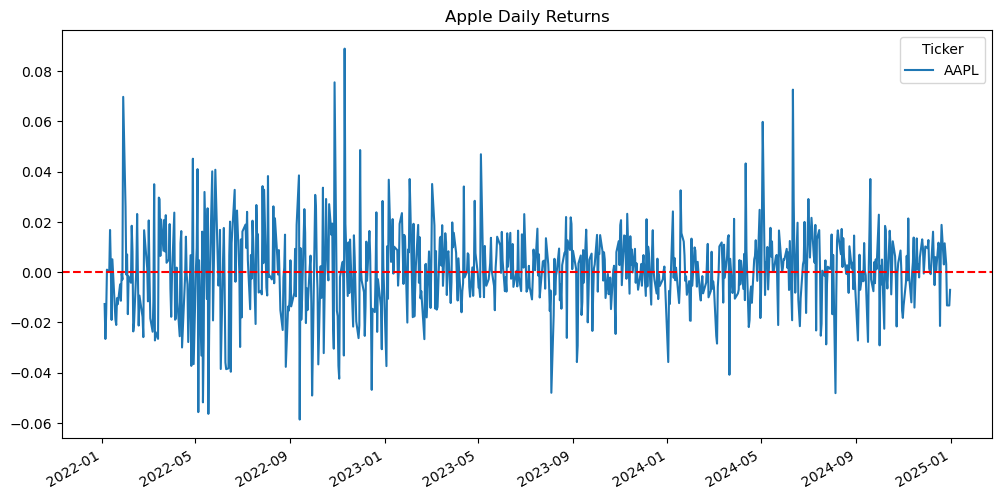

In [4]:
returns= data['Close'].pct_change()
print(returns.head(10))
returns.plot(figsize=(12,6),title='Apple Daily Returns')
plt.axhline(y=0, color = 'red',linestyle='--')
plt.show()

In [5]:
mean_ret = float(returns.mean())
std_ret = float(returns.std())


print(f"average daily return: {mean_ret:.4f}")
print(f"standard deviation:{std_ret:.4f}")
print(f"yearly return:{mean_ret * 252:.4f}")
print(f"yearly volitality:{std_ret * np.sqrt(252):.4f}")
print(f"sharp ration:{(mean_ret*252)/(std_ret * np.sqrt(252)):.4f}")

average daily return: 0.0006
standard deviation:0.0171
yearly return:0.1490
yearly volitality:0.2709
sharp ration:0.5498


/var/folders/kw/6g3k22sx06958rvhrf3y22140000gn/T/ipykernel_37263/3539354501.py:1: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  mean_ret = float(returns.mean())
/var/folders/kw/6g3k22sx06958rvhrf3y22140000gn/T/ipykernel_37263/3539354501.py:2: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  std_ret = float(returns.std())


In [6]:
tickers = ['AAPL', 'MSFT', 'GOOGL', 'AMZN', 'META', 
           'TSLA', 'NVDA', 'JPM', 'JNJ', 'XOM']
prices = yf.download(tickers, start='2020-01-01', end='2025-01-01')['Close']
print(prices.shape)
print(prices.head())

[*********************100%***********************]  10 of 10 completed

(1258, 10)
Ticker           AAPL       AMZN      GOOGL         JNJ         JPM  \
2020-01-02  72.271545  94.900497  67.788933  121.338547  117.313950   
2020-01-03  71.568924  93.748497  67.434319  119.933739  115.765823   
2020-01-06  72.139206  95.143997  69.231712  119.784050  115.673759   
2020-01-07  71.799919  95.343002  69.097992  120.515610  113.707237   
2020-01-08  72.954926  94.598503  69.589813  120.498962  114.594269   

Ticker            META        MSFT      NVDA       TSLA        XOM  
2020-01-02  207.789886  151.544250  5.957139  28.684000  52.606400  
2020-01-03  206.690399  149.657257  5.861787  29.534000  52.183464  
2020-01-06  210.583099  150.044098  5.886370  30.102667  52.584145  
2020-01-07  211.038742  148.676010  5.957636  31.270666  52.153786  
2020-01-08  213.178253  151.044250  5.968809  32.809334  51.367310  


In [7]:
monthly_prices = prices.resample('ME').last()
monthly_returns = monthly_prices.pct_change()

print(monthly_returns.tail())

Ticker          AAPL      AMZN     GOOGL       JNJ       JPM      META  \
2024-08-31  0.032353 -0.045352 -0.047569  0.058720  0.056391  0.097887   
2024-09-30  0.017467  0.043866  0.016465 -0.022911 -0.062011  0.099128   
2024-10-31 -0.030429  0.000376  0.031715 -0.013575  0.058901 -0.008490   
2024-11-30  0.051707  0.115290 -0.012623 -0.022559  0.125270  0.011875   
2024-12-31  0.055155  0.055318  0.121734 -0.067028 -0.040085  0.020306   

Ticker          MSFT      NVDA      TSLA       XOM  
2024-08-31 -0.001095  0.020082 -0.077390  0.002526  
2024-09-30  0.031548  0.017428  0.221942 -0.006105  
2024-10-31 -0.055659  0.093215 -0.045025 -0.003754  
2024-11-30  0.044192  0.041353  0.381469  0.018405  
2024-12-31 -0.004628 -0.028577  0.170008 -0.088081  


In [9]:
momentum = monthly_returns.rolling(12).sum()
latest_momentum = momentum.iloc[-1].sort_values(ascending=False)
print("the rank of momentum in past 12 months:")
print(latest_momentum)

the rank of momentum in past 12 months:
Ticker
NVDA     1.113187
TSLA     0.651615
META     0.565253
AMZN     0.391580
JPM      0.389228
GOOGL    0.328144
AAPL     0.287677
MSFT     0.137316
XOM      0.118379
JNJ     -0.036905
Name: 2024-12-31 00:00:00, dtype: float64


In [10]:
long_short_returns = []
for i in range(12, len(monthly_returns)):
    prev_momentum = momentum.iloc[i-1].dropna()
    
    long_stocks = prev_momentum.nlargest(3).index
    short_stocks = prev_momentum.nsmallest(3).index
    
    curr_returns = monthly_returns.iloc[i]
    
    portfolio_return = curr_returns[long_stocks].mean() - curr_returns[short_stocks].mean()
    long_short_returns.append(portfolio_return)

strategy_returns = pd.Series(long_short_returns, 
                              index=monthly_returns.index[12:])
print(strategy_returns.tail())

2024-08-31    0.029587
2024-09-30   -0.046127
2024-10-31    0.068660
2024-11-30    0.046153
2024-12-31    0.037127
Freq: ME, dtype: float64


annul return: 7.17%
annul volatility: 30.53%
Sharpe Ratio: 0.23
Max Drawdown: -42.44%


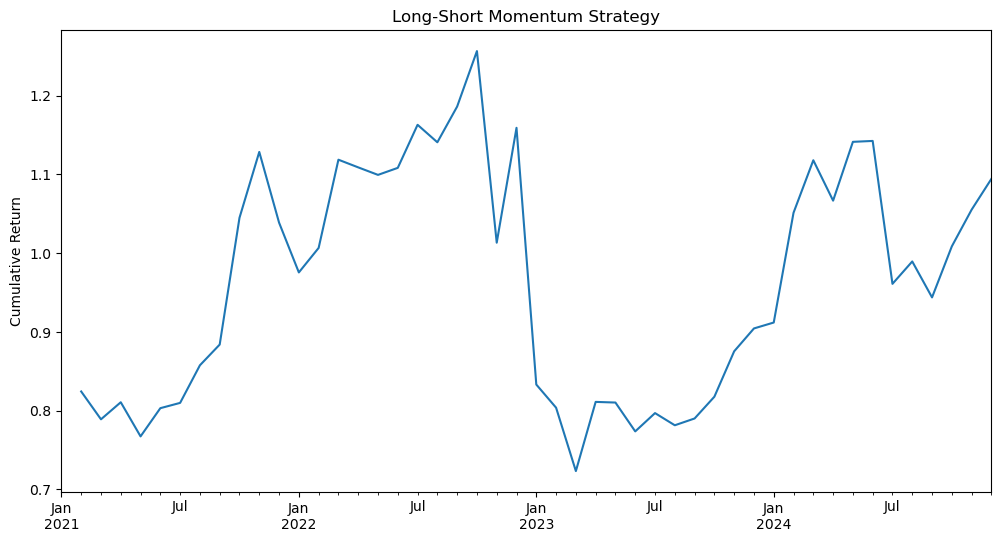

In [11]:
ann_return = strategy_returns.mean() * 12
ann_vol = strategy_returns.std() * np.sqrt(12)
sharpe = ann_return / ann_vol

# Max Drawdown
cumulative = (1 + strategy_returns).cumprod()
rolling_max = cumulative.cummax()
drawdown = (cumulative - rolling_max) / rolling_max
max_drawdown = drawdown.min()

print(f"annul return: {ann_return:.2%}")
print(f"annul volatility: {ann_vol:.2%}")
print(f"Sharpe Ratio: {sharpe:.2f}")
print(f"Max Drawdown: {max_drawdown:.2%}")

# cumulative return curve
cumulative.plot(figsize=(12,6), title='Long-Short Momentum Strategy')
plt.ylabel('Cumulative Return')
plt.show()

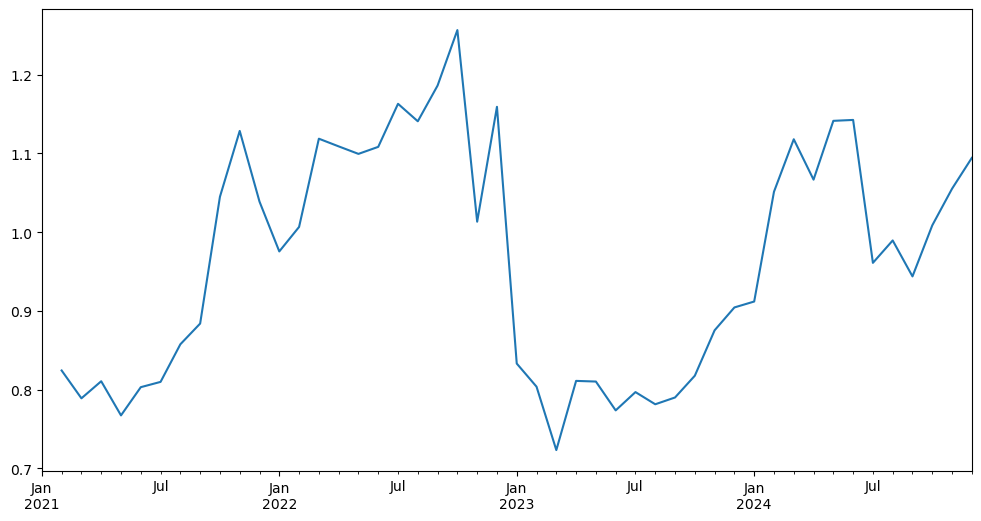

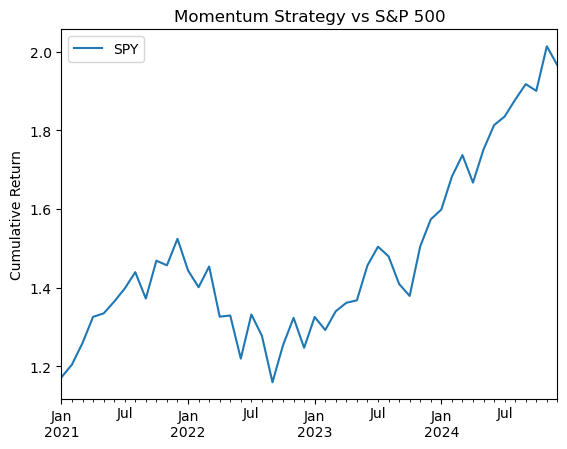

In [18]:
plt.close('all')

start = cumulative.index[0]
end = cumulative.index[-1]

plt.figure(figsize=(12,6))
cumulative.plot(label='Momentum Strategy')
spy_cumulative.loc[start:end].plot(label='S&P 500 (SPY)')
plt.title('Momentum Strategy vs S&P 500')
plt.ylabel('Cumulative Return')
plt.legend()
plt.show()

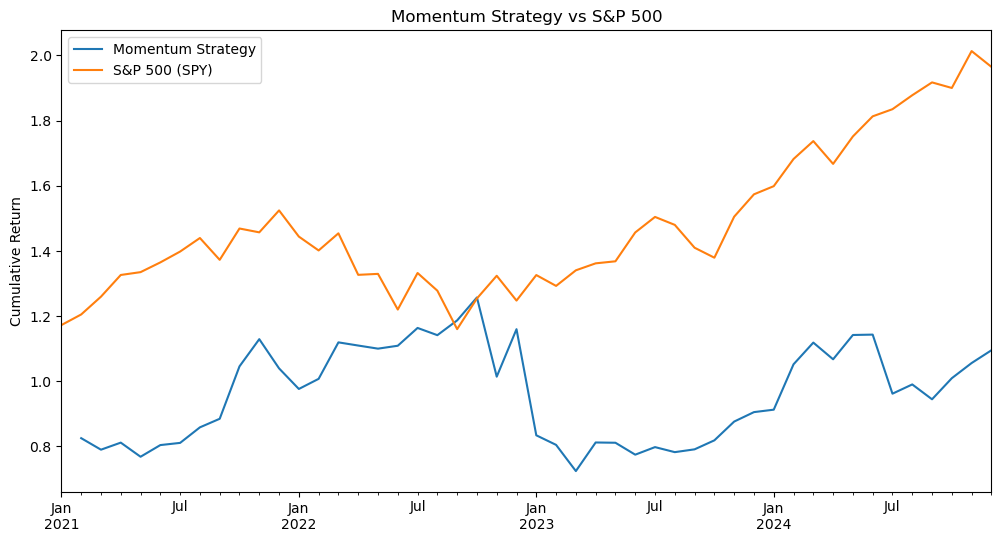

In [22]:
plt.close('all')

plt.figure(figsize=(12,6))
cumulative.squeeze().plot(label='Momentum Strategy')
spy_cum.loc[strategy_returns.index].squeeze().plot(label='S&P 500 (SPY)')
plt.title('Momentum Strategy vs S&P 500')
plt.ylabel('Cumulative Return')
plt.legend()
plt.show()